# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Prima Surya Nusantara | 5054251036 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
N_INIT = 20
sns.set_theme(style='whitegrid', palette='Set2')
pd.set_option('display.max_columns', 30)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__}')
print(f'scikit-learn {sklearn.__version__} | SciPy {scipy.__version__}')


Python 3.12.14 | pandas 3.1.1 | NumPy 2.5.4
scikit-learn 1.9.1 | SciPy 1.18.1


In [2]:
# Mendukung Run All dari folder notebook maupun root repositori.
data_path = Path('Live.csv')
if not data_path.exists():
    data_path = Path('6. KMeans_Hierarchical Clustering/Live.csv')
df = pd.read_csv(data_path)
count_cols = [c for c in df if c.startswith('num_')]
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
print('Ukuran data:', df.shape)
display(df.head())
df.info()
display(df.describe().T)
display(df.isna().sum().rename('missing').to_frame())
print('Duplikat seluruh kolom:', df.duplicated().sum())
print('Jumlah status_id unik:', df['status_id'].nunique())
print('Kolom seluruhnya kosong:', df.columns[df.isna().all()].tolist())


Ukuran data: (7050, 16)


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), str(2)
memory usage: 881.4 

,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


,missing
status_id,0
status_type,0
status_published,0
num_reactions,0
num_comments,0
num_shares,0
num_likes,0
num_loves,0
num_wows,0
num_hahas,0


Duplikat seluruh kolom: 0
Jumlah status_id unik: 7050
Kolom seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


,skewness,nol_persen,median,maksimum,varians
num_reactions,3.738,1.716,59.5,4710,214022.177
num_comments,9.029,30.057,4.0,20990,791453.671
num_shares,7.099,55.475,0.0,3424,17318.551
num_likes,3.919,1.787,58.0,4710,202025.400
num_loves,6.005,60.000,0.0,657,1597.835
num_wows,18.247,75.291,0.0,278,76.032
num_hahas,20.306,83.915,0.0,157,15.659
num_sads,17.579,91.390,0.0,51,2.551
num_angrys,19.507,94.000,0.0,31,0.528


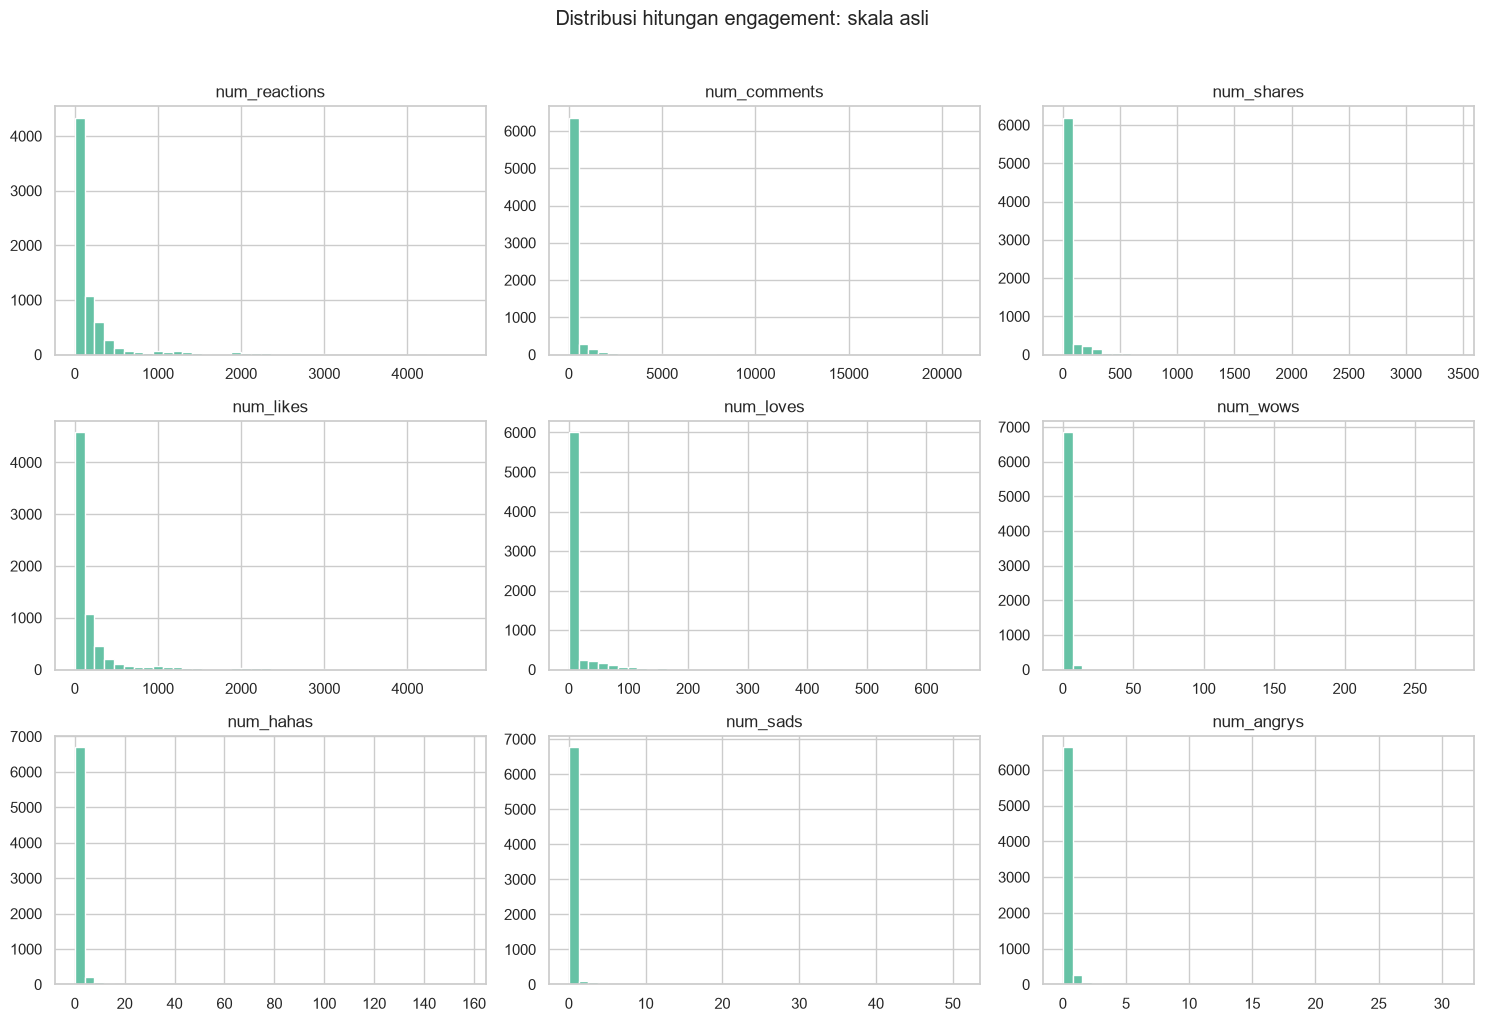

In [3]:
distribution = pd.DataFrame({
    'skewness': df[count_cols].skew(),
    'nol_persen': df[count_cols].eq(0).mean() * 100,
    'median': df[count_cols].median(),
    'maksimum': df[count_cols].max(),
    'varians': df[count_cols].var(),
})
display(distribution.round(3))
df[count_cols].hist(bins=40, figsize=(15, 10))
plt.suptitle('Distribusi hitungan engagement: skala asli', y=1.02)
plt.tight_layout()
plt.show()


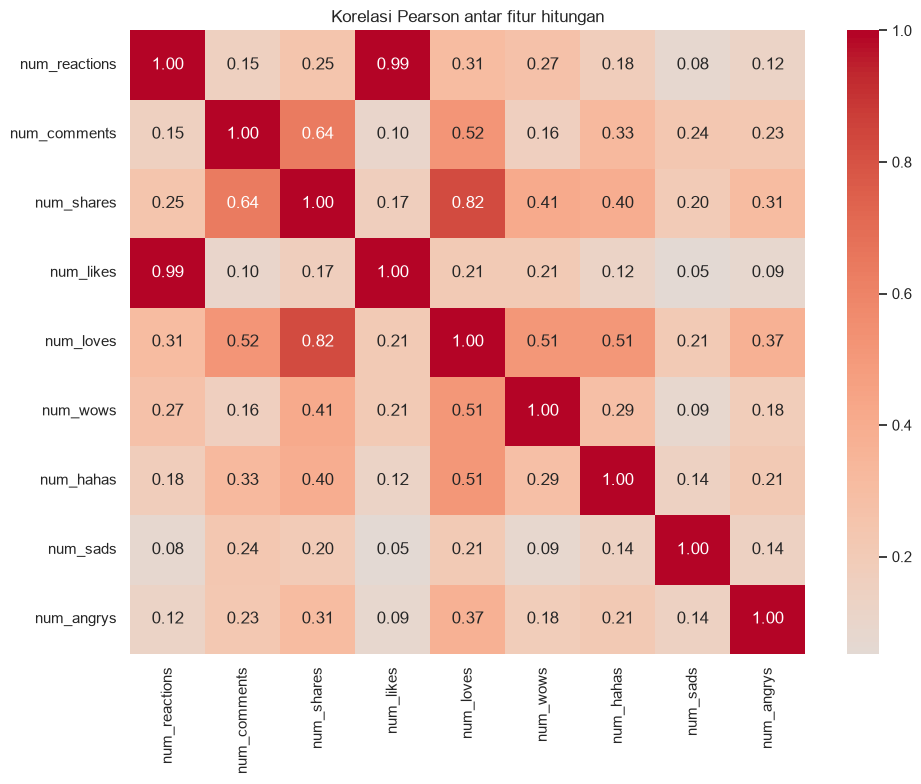

Baris num_reactions tidak sama dengan jumlah rincian reaksi: 9


,jumlah
selisih,
0,7041
1,3
2,3
3,2
4,1


In [4]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Korelasi Pearson antar fitur hitungan')
plt.tight_layout()
plt.show()
reaction_gap = df['num_reactions'] - df[['num_likes'] + emoji_cols].sum(axis=1)
print('Baris num_reactions tidak sama dengan jumlah rincian reaksi:', reaction_gap.ne(0).sum())
display(reaction_gap.value_counts().rename_axis('selisih').rename('jumlah').to_frame())


Tanggal tidak valid: 0


,jumlah_posting,emoji_persen
tahun,,
2012,589,0.00
2013,500,0.00
2014,233,0.00
2015,337,0.00
2016,588,68.03
2017,2253,54.19
2018,2550,57.76


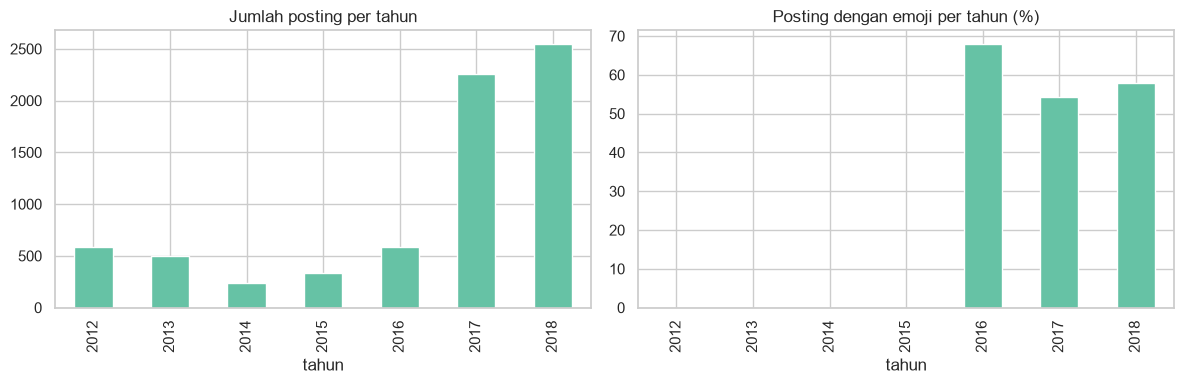

In [5]:
df['status_published'] = pd.to_datetime(df['status_published'], format='%m/%d/%Y %H:%M', errors='coerce')
print('Tanggal tidak valid:', df['status_published'].isna().sum())
annual = df.assign(tahun=df['status_published'].dt.year,
                   memiliki_emoji=df[emoji_cols].sum(axis=1).gt(0)).groupby('tahun').agg(
    jumlah_posting=('status_id', 'size'),
    proporsi_emoji=('memiliki_emoji', 'mean'))
annual['emoji_persen'] = annual.pop('proporsi_emoji') * 100
display(annual.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
annual['jumlah_posting'].plot.bar(ax=axes[0], title='Jumlah posting per tahun')
annual['emoji_persen'].plot.bar(ax=axes[1], title='Posting dengan emoji per tahun (%)')
plt.tight_layout()
plt.show()


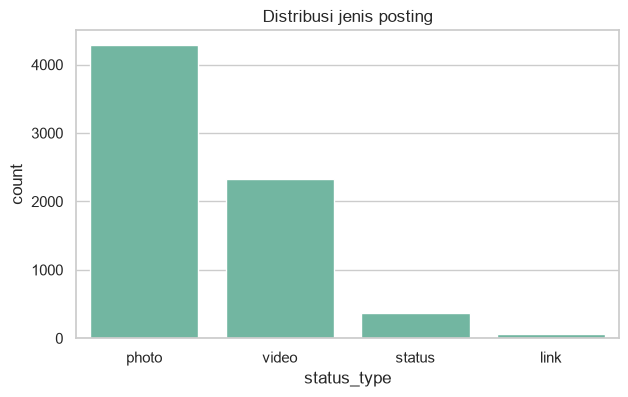

,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x='status_type', order=df['status_type'].value_counts().index, ax=ax)
ax.set_title('Distribusi jenis posting')
plt.show()
display(df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median())


## EDA tambahan dan keputusan awal

Pemeriksaan identitas total reaksi di atas membantu mendeteksi redundansi secara definisi,
bukan hanya berdasarkan korelasi. Distribusi tahunan juga diperiksa karena nol pada reaksi
emoji dapat mencerminkan periode pencatatan yang berbeda, bukan semata-mata minat pengguna.
Hubungan waktu ini bersifat observasional; dataset tidak membuktikan penyebabnya.


# 2. Preprocessing

In [7]:
empty_cols = df.columns[df.isna().all()].tolist()
clean = df.drop(columns=empty_cols).copy()
# ID bukan dasar duplikat: periksa seluruh isi posting yang tersedia selain ID.
duplicate_subset = [c for c in clean if c != 'status_id']
n_duplicates = int(clean.duplicated(subset=duplicate_subset).sum())
print('Duplikat isi selain status_id:', n_duplicates)
clean = clean.drop_duplicates(subset=duplicate_subset).reset_index(drop=True)
print('Missing setelah kolom kosong dihapus:')
display(clean.isna().sum().to_frame('missing'))
assert clean[count_cols].notna().all().all(), 'Perlu penanganan missing pada fitur hitungan.'
assert clean[count_cols].ge(0).all().all(), 'Hitungan tidak boleh negatif.'
q1, q3 = clean[count_cols].quantile(.25), clean[count_cols].quantile(.75)
iqr = q3 - q1
outlier_report = pd.DataFrame({
    'batas_atas_IQR': q3 + 1.5 * iqr,
    'di_atas_batas': clean[count_cols].gt(q3 + 1.5 * iqr).sum(),
    'maksimum': clean[count_cols].max(),
})
display(outlier_report)
print('Ukuran data bersih:', clean.shape)
print('Outlier dipertahankan sebagai posting berengagement tinggi yang mungkin valid; pengaruhnya dikurangi dengan log1p.')


Duplikat isi selain status_id: 54
Missing setelah kolom kosong dihapus:


,missing
status_id,0
status_type,0
status_published,0
num_reactions,0
num_comments,0
num_shares,0
num_likes,0
num_loves,0
num_wows,0
num_hahas,0


,batas_atas_IQR,di_atas_batas,maksimum
num_reactions,514.500,689,4710
num_comments,55.625,1365,20990
num_shares,10.000,1382,3424
num_likes,429.500,754,4710
num_loves,7.500,1303,657
num_wows,0.000,1702,278
num_hahas,0.000,1117,157
num_sads,0.000,598,51
num_angrys,0.000,420,31


Ukuran data bersih: (6996, 12)
Outlier dipertahankan sebagai posting berengagement tinggi yang mungkin valid; pengaruhnya dikurangi dengan log1p.


In [8]:
metadata = clean[['status_type', 'status_published']].copy()
features = clean[['num_likes', 'num_comments', 'num_shares']].copy()
features['num_emoji'] = clean[emoji_cols].sum(axis=1)
feature_cols = features.columns.tolist()
assert all(pd.api.types.is_numeric_dtype(features[c]) for c in feature_cols)
assert 'status_type' not in feature_cols and 'status_id' not in feature_cols
display(features.head())
display(features.eq(0).mean().mul(100).to_frame('nol_persen'))


,num_likes,num_comments,num_shares,num_emoji
0,432,512,262,97
1,150,0,0,0
2,204,236,57,23
3,111,0,0,0
4,204,0,0,9


,nol_persen
num_likes,1.758148
num_comments,30.245855
num_shares,55.817610
num_emoji,56.503716


**Fitur yang dipilih:** `num_likes`, `num_comments`, `num_shares`, dan `num_emoji`.

- Like, komentar, dan share mewakili bentuk engagement yang berbeda.
- `num_emoji` menjumlahkan love, wow, haha, sad, dan angry. Penggabungan mengurangi
  sparsitas serta mencegah beberapa jenis emoji langka mendapat bobot tersendiri
  setelah standardisasi. Konsekuensinya, makna/sentimen tiap jenis emoji tidak dibedakan.
- `num_reactions` dihapus karena merupakan total yang sangat bertumpang tindih dengan
  like dan emoji. Selisih kecil yang terdeteksi dilaporkan pada EDA, bukan dianggap fitur baru.
- `status_id` dan kolom kosong dihapus; jenis dan waktu posting hanya untuk interpretasi.
  Duplikat isi dibuang dengan mengabaikan ID. Tanpa teks posting, kesamaan ini adalah
  duplikat observasi berdasarkan kolom yang tersedia, belum tentu bukti posting identik.
- Tidak dilakukan clipping/penghapusan outlier otomatis karena posting viral masih relevan.
  Fitur hitungan lengkap tidak memiliki missing; tidak perlu imputasi.


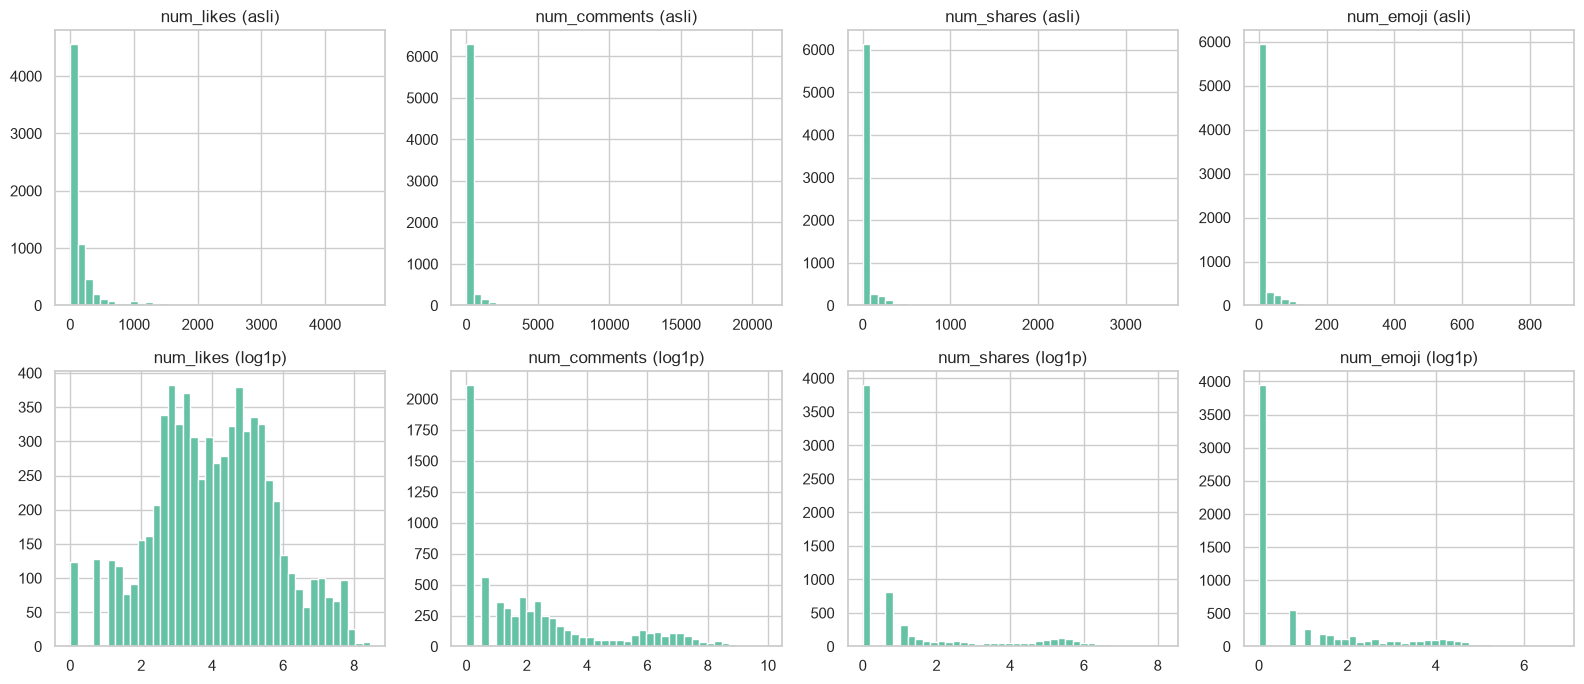

,skew_asli,skew_log1p
num_likes,3.932518,-0.012163
num_comments,8.994234,1.047660
num_shares,7.072010,1.529132
num_emoji,6.972702,1.311034


In [9]:
X_raw = features.to_numpy(dtype=float)
X_log = np.log1p(X_raw)
fig, axes = plt.subplots(2, len(feature_cols), figsize=(16, 7))
for j, col in enumerate(feature_cols):
    axes[0, j].hist(X_raw[:, j], bins=40)
    axes[0, j].set_title(col + ' (asli)')
    axes[1, j].hist(X_log[:, j], bins=40)
    axes[1, j].set_title(col + ' (log1p)')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'skew_asli': features.skew(),
                      'skew_log1p': pd.DataFrame(X_log, columns=feature_cols).skew()}))


In [10]:
raw_scaler = StandardScaler()
log_scaler = StandardScaler()
X_raw_scaled = raw_scaler.fit_transform(X_raw)
X_log_scaled = log_scaler.fit_transform(X_log)
assert np.isfinite(X_log_scaled).all()
display(pd.DataFrame(X_log_scaled, columns=feature_cols).agg(['mean', 'std']).round(4))

# Evaluasi silhouette seluruh baris, tanpa sampling. chunking membatasi memori jarak.
sklearn.set_config(working_memory=256)
def silhouette(labels):
    return silhouette_score(X_log_scaled, labels, metric='euclidean')

def sizes(labels):
    return pd.Series(labels).value_counts().sort_index().to_dict()


,num_likes,num_comments,num_shares,num_emoji
mean,-0.0000,-0.0000,0.0000,-0.0000
std,1.0001,1.0001,1.0001,1.0001


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
representations = {'Mentah': X_raw, 'Scaling': X_raw_scaled, 'Log + scaling': X_log_scaled}
comparison_models = {}
for name, X in representations.items():
    comparison_models[name] = KMeans(n_clusters=3, random_state=RANDOM_STATE,
                                     n_init=N_INIT).fit(X)


In [12]:
preprocessing_comparison = pd.DataFrame([
    {'representasi': name, 'silhouette_ruang_log_scaled': silhouette(model.labels_),
     'jumlah_anggota': sizes(model.labels_)}
    for name, model in comparison_models.items()
]).set_index('representasi')
display(preprocessing_comparison)
variance_share = features.var() / features.var().sum() * 100
display(variance_share.sort_values(ascending=False).to_frame('kontribusi_varians_asli_persen'))


,silhouette_ruang_log_scaled,jumlah_anggota
representasi,,
Mentah,0.273068,"{0: 6392, 1: 137, 2: 467}"
Scaling,0.253268,"{0: 373, 1: 6277, 2: 346}"
Log + scaling,0.463799,"{0: 1131, 1: 2258, 2: 3607}"


,kontribusi_varians_asli_persen
num_comments,78.916490
num_likes,19.129405
num_shares,1.726497
num_emoji,0.227608


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
k_values = list(range(2, 11))
k_models = {k: KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_log_scaled)
            for k in k_values}
inertias = np.array([k_models[k].inertia_ for k in k_values])


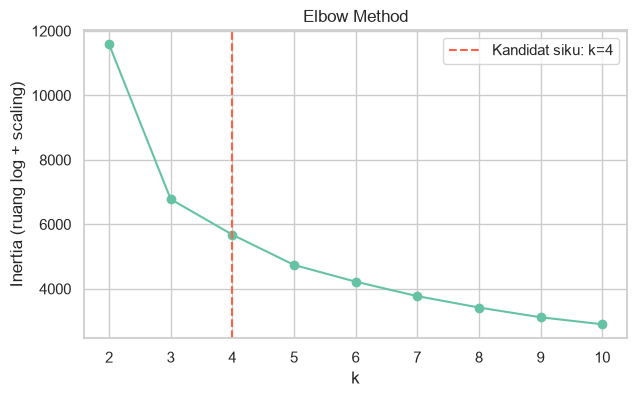

In [14]:
# Kandidat siku: jarak vertikal terbesar terhadap garis antara dua ujung kurva
# setelah normalisasi kedua sumbu. Ini heuristik, bukan kepastian statistik.
x_norm = (np.array(k_values) - min(k_values)) / (max(k_values) - min(k_values))
y_norm = (inertias - inertias.min()) / (inertias.max() - inertias.min())
elbow_k = k_values[int(np.argmax((1 - x_norm) - y_norm))]
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, 'o-')
plt.axvline(elbow_k, ls='--', color='tomato', label=f'Kandidat siku: k={elbow_k}')
plt.xticks(k_values)
plt.xlabel('k')
plt.ylabel('Inertia (ruang log + scaling)')
plt.title('Elbow Method')
plt.legend()
plt.show()


## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
silhouette_values = [silhouette(k_models[k].labels_) for k in k_values]
k_search = pd.DataFrame({'k': k_values, 'inertia': inertias, 'silhouette': silhouette_values})
display(k_search.round(4))


,k,inertia,silhouette
0,2,11586.9022,0.5899
1,3,6779.8371,0.4638
2,4,5678.2509,0.3372
3,5,4739.9565,0.3586
4,6,4220.2763,0.3469
5,7,3772.1024,0.3367
6,8,3418.5657,0.3154
7,9,3116.4281,0.3293
8,10,2898.9966,0.3164


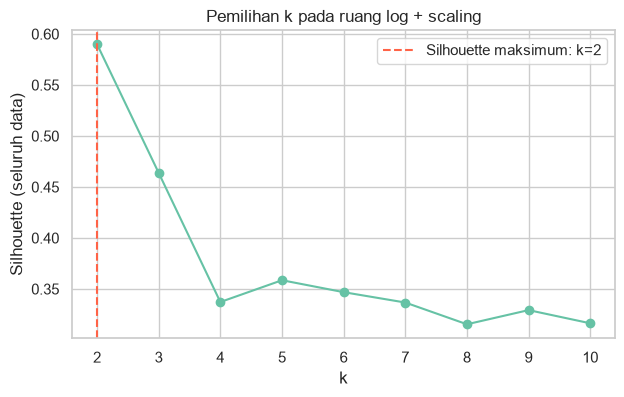

Kandidat Elbow: 4; pilihan final berdasarkan Silhouette: 2


In [16]:
best_k = int(k_search.loc[k_search['silhouette'].idxmax(), 'k'])
plt.figure(figsize=(7, 4))
plt.plot(k_values, silhouette_values, 'o-')
plt.axvline(best_k, ls='--', color='tomato', label=f'Silhouette maksimum: k={best_k}')
plt.xticks(k_values)
plt.xlabel('k')
plt.ylabel('Silhouette (seluruh data)')
plt.title('Pemilihan k pada ruang log + scaling')
plt.legend()
plt.show()
print(f'Kandidat Elbow: {elbow_k}; pilihan final berdasarkan Silhouette: {best_k}')


**Pilihan k untuk K-Means: 2.** Silhouette maksimum pada rentang 2–10 adalah
**0,5899** (k=2), dibandingkan 0,4638 (k=3) dan 0,3372 (k=4).
Heuristik jarak terhadap garis ujung kurva Elbow menunjuk **k=4**, tetapi penurunan
inertia paling tajam terjadi dari k=2 ke 3 (11.586,90 menjadi 6.779,84), lalu melandai.
Karena siku tidak tunggal/tegas, k=3–4 dapat dipertimbangkan untuk segmentasi lebih rinci.
Untuk model final, k=2 diprioritaskan karena pemisahan terukur lebih baik serta lebih
sederhana diinterpretasikan. Ini pilihan terbaik dalam konfigurasi yang diuji,
bukan jumlah segmen yang pasti benar secara bisnis.


## 3.4 Model K-Means Final

In [17]:
kmeans_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT)
labels_kmeans = kmeans_final.fit_predict(X_log_scaled)


In [18]:
def cluster_profile(labels):
    frame = features.assign(cluster=labels)
    return frame.groupby('cluster').agg(jumlah=('num_likes', 'size')).join(
        frame.groupby('cluster')[feature_cols].median().add_prefix('median_')).join(
        frame.groupby('cluster')[feature_cols].mean().add_prefix('mean_'))

profile_kmeans = cluster_profile(labels_kmeans)
display(profile_kmeans.round(2))


,jumlah,median_num_likes,median_num_comments,median_num_shares,median_num_emoji,mean_num_likes,mean_num_comments,mean_num_shares,mean_num_emoji
cluster,,,,,,,,,
0,5618,33.0,2.0,0.0,0.0,168.76,7.15,1.34,1.33
1,1378,191.0,524.0,141.5,48.0,378.33,1116.45,199.00,70.98


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [19]:
# Seluruh data bersih, tidak disampling. Jarak Euclidean untuk Ward.
Z_ward = linkage(X_log_scaled, method='ward', metric='euclidean')
print('Ukuran linkage matrix:', Z_ward.shape)


Ukuran linkage matrix: (6995, 4)


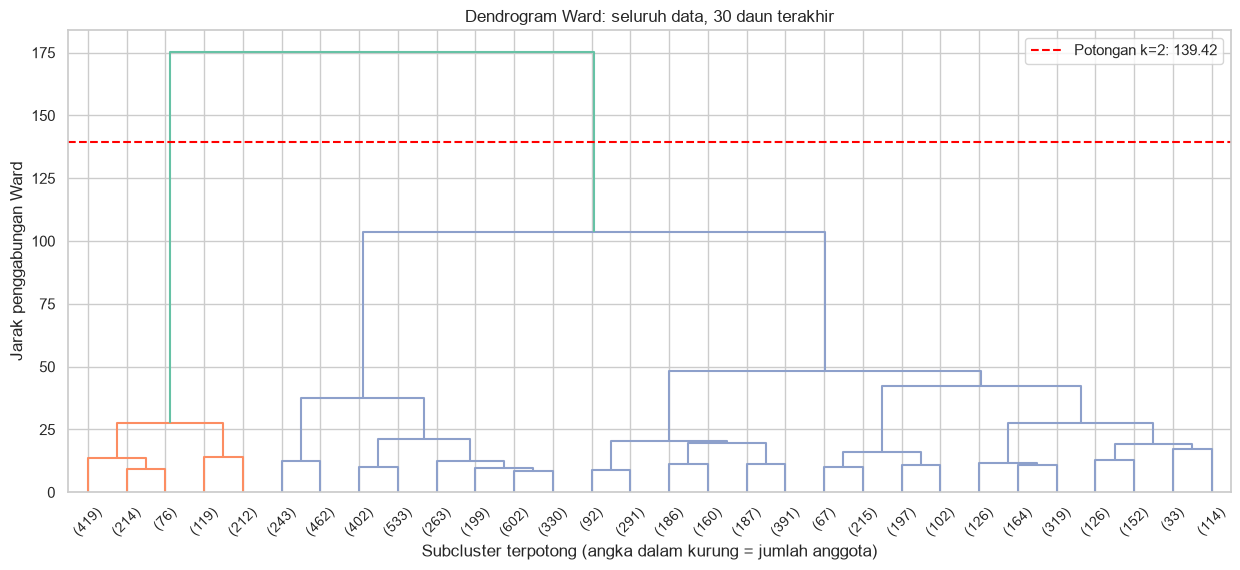

Interval potong untuk 2 cluster: (103.70, 175.13)


In [ ]:
lower_height = Z_ward[-best_k, 2]
upper_height = Z_ward[-(best_k - 1), 2]
cut_height = (lower_height + upper_height) / 2
plt.figure(figsize=(15, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=30, show_leaf_counts=True,
           color_threshold=cut_height)
plt.axhline(cut_height, color='red', ls='--', label=f'Potongan k={best_k}: {cut_height:.2f}')
plt.xlabel('Subcluster terpotong (angka dalam kurung = jumlah anggota)')
plt.ylabel('Jarak penggabungan Ward')
plt.title('Dendrogram Ward: seluruh data, 30 daun terakhir')
plt.legend()
plt.show()
print(f'Interval potong untuk {best_k} cluster: ({lower_height:.2f}, {upper_height:.2f})')


## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [21]:
hc_models = {}
for method in ['ward', 'complete', 'average', 'single']:
    hc_models[method] = AgglomerativeClustering(n_clusters=best_k, linkage=method,
                                               metric='euclidean').fit(X_log_scaled)


In [22]:
linkage_comparison = pd.DataFrame([
    {'linkage': method, 'silhouette': silhouette(model.labels_),
     'anggota_terkecil': min(sizes(model.labels_).values()),
     'proporsi_terbesar': max(sizes(model.labels_).values()) / len(clean),
     'jumlah_anggota': sizes(model.labels_)}
    for method, model in hc_models.items()
]).set_index('linkage')
display(linkage_comparison)
# Hindari segmentasi degeneratif: tiap cluster minimal 1% data dan terbesar <= 95%.
eligible = linkage_comparison[
    (linkage_comparison['anggota_terkecil'] >= .01 * len(clean)) &
    (linkage_comparison['proporsi_terbesar'] <= .95)]
if eligible.empty:
    best_linkage = 'ward'
    print('Tidak ada linkage memenuhi batas ukuran; Ward dipakai sebagai baseline, periksa ketimpangan.')
else:
    best_linkage = eligible['silhouette'].idxmax()
print('Pilihan linkage:', best_linkage)


,silhouette,anggota_terkecil,proporsi_terbesar,jumlah_anggota
linkage,,,,
ward,0.595095,1040,0.851344,"{0: 5956, 1: 1040}"
complete,0.505746,460,0.934248,"{0: 6536, 1: 460}"
average,0.592165,1232,0.823899,"{0: 1232, 1: 5764}"
single,0.387694,1,0.999857,"{0: 6995, 1: 1}"


Pilihan linkage: ward


**Pilihan linkage: Ward**, dengan Silhouette **0,5951**, tertinggi di antara keempat
metode. Ukuran clusternya 5.956 dan 1.040, sehingga tetap memisahkan dua kelompok yang
cukup besar. Average mendekati Ward (0,5922), complete lebih rendah (0,5057), sedangkan
single menghasilkan satu cluster berisi 6.995 baris dan satu singleton (0,3877).

Sebagai pertimbangan segmentasi, kode menyaring kandidat dengan setiap cluster minimal
1% data dan cluster terbesar maksimal 95%. Batas ini merupakan pilihan praktis untuk
menghindari solusi degeneratif, bukan ketentuan statistik universal. Ward tetap menang
bahkan tanpa penyaringan tersebut. Seluruh hasil tetap dilaporkan untuk transparansi.


## 4.3 Model Hierarchical Clustering Final

In [23]:
hc_final = AgglomerativeClustering(n_clusters=best_k, linkage=best_linkage, metric='euclidean')
labels_hc = hc_final.fit_predict(X_log_scaled)


In [24]:
profile_hc = cluster_profile(labels_hc)
display(profile_hc.round(2))


,jumlah,median_num_likes,median_num_comments,median_num_shares,median_num_emoji,mean_num_likes,mean_num_comments,mean_num_shares,mean_num_emoji
cluster,,,,,,,,,
0,5956,38.0,2.0,0.0,0.0,198.25,15.32,2.71,2.27
1,1040,168.0,815.5,193.5,60.5,277.53,1430.19,255.40,88.24


# 5. Evaluasi Model

In [25]:
evaluation = pd.DataFrame([
    {'model': name, 'Silhouette': silhouette(labels),
     'Davies-Bouldin': davies_bouldin_score(X_log_scaled, labels),
     'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, labels)}
    for name, labels in [('K-Means', labels_kmeans), (f'HC ({best_linkage})', labels_hc)]
]).set_index('model')
display(evaluation.round(4))
ari = adjusted_rand_score(labels_kmeans, labels_hc)
print(f'Adjusted Rand Index antarmodel: {ari:.4f} (kesesuaian partisi, bukan akurasi)')


,Silhouette,Davies-Bouldin,Calinski-Harabasz
model,,,
K-Means,0.5899,0.6050,9897.4946
HC (ward),0.5951,0.4987,8479.5877


Adjusted Rand Index antarmodel: 0.7753 (kesesuaian partisi, bukan akurasi)


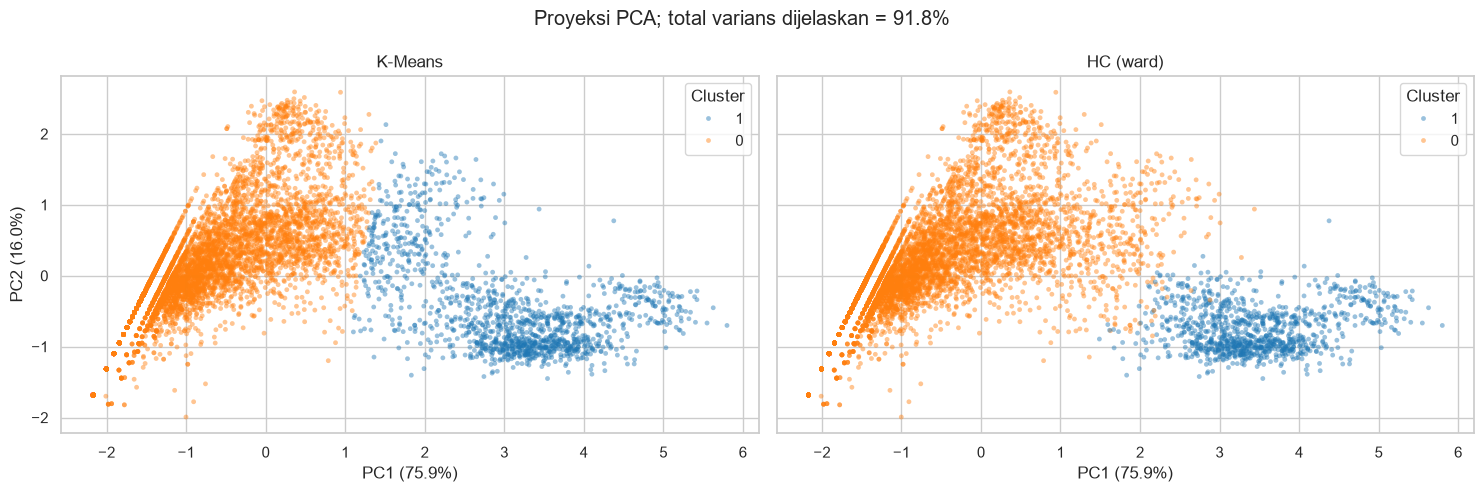

Nomor cluster bersifat arbitrer; warna/nomor yang sama antarmodel tidak menjamin segmen sama.


In [26]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coordinates = pca.fit_transform(X_log_scaled)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)
for ax, name, labels in zip(axes, ['K-Means', f'HC ({best_linkage})'], [labels_kmeans, labels_hc]):
    sns.scatterplot(x=coordinates[:, 0], y=coordinates[:, 1], hue=labels.astype(str),
                    palette='tab10', s=12, alpha=.45, linewidth=0, ax=ax)
    ax.set_title(name)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.legend(title='Cluster')
plt.suptitle(f'Proyeksi PCA; total varians dijelaskan = {pca.explained_variance_ratio_.sum():.1%}')
plt.tight_layout()
plt.show()
print('Nomor cluster bersifat arbitrer; warna/nomor yang sama antarmodel tidak menjamin segmen sama.')


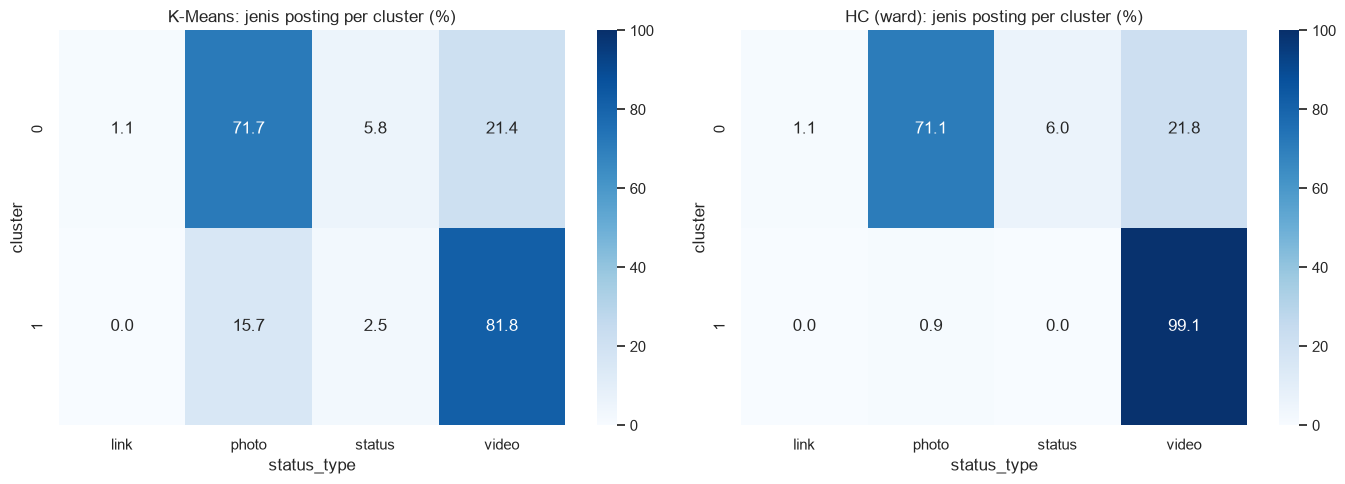

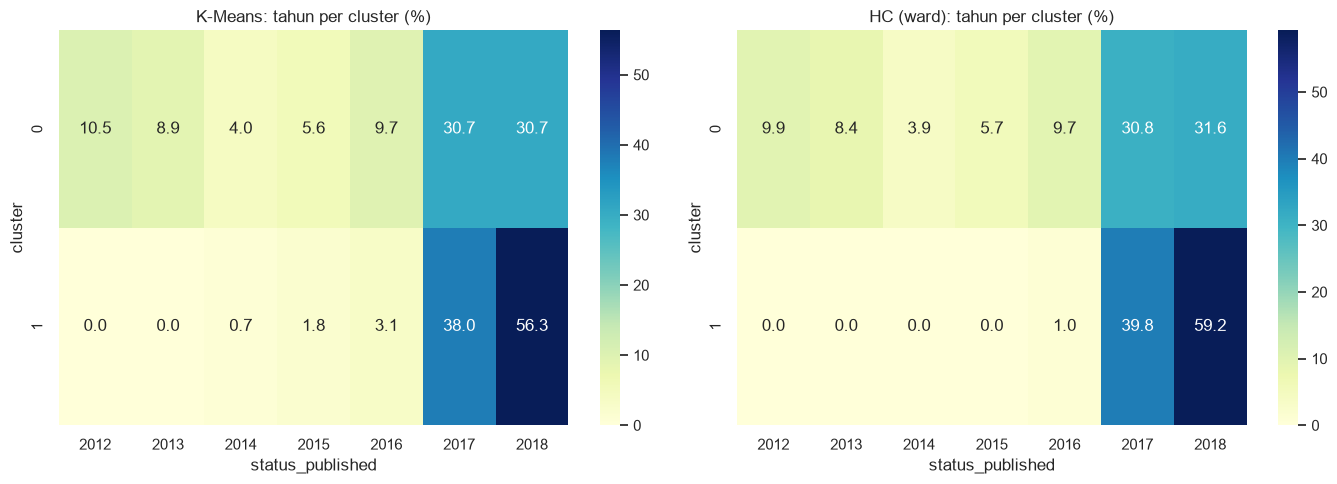

In [27]:
composition_kmeans = pd.crosstab(pd.Series(labels_kmeans, name='cluster'), metadata['status_type'], normalize='index') * 100
composition_hc = pd.crosstab(pd.Series(labels_hc, name='cluster'), metadata['status_type'], normalize='index') * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in zip(axes, [composition_kmeans, composition_hc], ['K-Means', f'HC ({best_linkage})']):
    sns.heatmap(table, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, ax=ax)
    ax.set_title(title + ': jenis posting per cluster (%)')
plt.tight_layout()
plt.show()
# Interpretasi tambahan waktu; tanggal tidak pernah masuk fitur clustering.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, labels, title in zip(axes, [labels_kmeans, labels_hc], ['K-Means', f'HC ({best_linkage})']):
    table = pd.crosstab(pd.Series(labels, name='cluster'), metadata['status_published'].dt.year, normalize='index') * 100
    sns.heatmap(table, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax)
    ax.set_title(title + ': tahun per cluster (%)')
plt.tight_layout()
plt.show()


# 6. Analisis

### 6.1 Kualitas data dan pemilihan fitur

Data awal berisi **7.050 baris dan 16 kolom**. Empat kolom seluruhnya kosong dihapus.
Sebanyak **54 baris memiliki isi sama jika `status_id` diabaikan**, sehingga data bersih
berisi **6.996 baris**. Kesamaan kolom yang tersedia digunakan sebagai definisi duplikat
observasi; dataset tanpa teks tidak membuktikan bahwa semua itu posting yang sama.
Tidak ada missing pada fitur hitungan dan seluruh tanggal berhasil dikonversi.

`num_reactions` dikeluarkan agar total reaksi tidak memberi bobot ganda bersama rinciannya.
Pemeriksaan menemukan **9 baris** dengan total reaksi berbeda dari jumlah like dan emoji.
Baris tersebut dipertahankan karena komponen fitur masih tersedia dan tidak negatif;
total yang tidak konsisten tidak digunakan. Love, wow, haha, sad, dan angry digabung menjadi
`num_emoji`. Pada data awal, sad bernilai nol pada **91,39%** baris dan angry pada **94,00%**.
Standardisasi tiap emoji secara terpisah dapat membesarkan pengaruh kejadian langka.
Penggabungan mengurangi masalah itu, dengan konsekuensi hilangnya informasi jenis reaksi.

### 6.2 Pengaruh log dan scaling

Pada empat fitur terpilih, **78,92% varians mentah** berasal dari komentar, **19,13%**
dari like, sedangkan emoji hanya **0,23%**. Karena jarak Euclidean mengkuadratkan selisih,
K-Means mentah mudah didominasi komentar ekstrem (maksimum 20.990). Outlier tidak otomatis
dibuang karena dapat merupakan posting viral yang sah. `log1p` menekan rentang ekstrem
dan tetap terdefinisi untuk nol, lalu StandardScaler menyetarakan skala tiap fitur.

Perbandingan berikut memakai **k=3** dan menghitung semua Silhouette pada ruang
**log + scaling yang sama**, sehingga perubahan nilai bukan sekadar perubahan skala evaluasi.

| Representasi saat pelatihan | Anggota cluster (urut label) | Silhouette pada ruang bersama |
|---|---|---:|
| Mentah | 6.392; 137; 467 | 0,2731 |
| Scaling | 373; 6.277; 346 | 0,2533 |
| Log + scaling | 1.131; 2.258; 3.607 | 0,4638 |

Scaling saja belum mengatasi kemencengan dan bahkan memberi skor lebih rendah pada
ruang evaluasi bersama. Kombinasi log dan scaling menghasilkan pemisahan lebih baik dan
ukuran cluster lebih tersebar. Hasil ini tidak mengharuskan cluster seimbang, tetapi
menunjukkan bahwa solusi awal terlalu berfokus pada sedikit observasi ekstrem.

### 6.3 Jumlah cluster dan dendrogram

Silhouette memilih **k=2 (0,5899)**, sedangkan kandidat siku otomatis adalah **k=4**.
Grafik inertia turun dari **11.586,90 (k=2)** ke **6.779,84 (k=3)**, kemudian ke
**5.678,25 (k=4)**. Kurva mendukung pembagian lebih rinci sekitar k=3–4, tetapi
Silhouette k=3 dan k=4 turun menjadi 0,4638 dan 0,3372. Karena itu, model final memakai
k=2 sebagai dua segmen utama, dengan k=3–4 sebagai alternatif bila diperlukan rincian.
Kandidat Elbow sensitif terhadap rentang k dan metode pendeteksian, sehingga bukan
bukti tunggal jumlah cluster optimal.

Pada dendrogram Ward seluruh data, pemotongan di antara tinggi **103,70 dan 175,13**
(garis contoh sekitar **139,42**) menghasilkan dua cluster. Ini konsisten dengan
pemisahan besar terakhir pada hierarki. Jumlah cluster HC dibuat sama dengan K-Means
untuk perbandingan terkontrol, bukan dioptimalkan secara terpisah untuk tiap linkage.

### 6.4 Perbandingan linkage

| Linkage | Anggota cluster | Silhouette |
|---|---|---:|
| Ward | 5.956; 1.040 | 0,5951 |
| Complete | 6.536; 460 | 0,5057 |
| Average | 1.232; 5.764 | 0,5922 |
| Single | 6.995; 1 | 0,3877 |

Ward menggabungkan kelompok berdasarkan kenaikan jumlah kuadrat dalam cluster,
sehingga cocok untuk kelompok relatif kompak di ruang yang distandardisasi. Average
hampir sama baiknya pada metrik ini. Complete memakai jarak pasangan terjauh sehingga
pemisahannya lebih konservatif dan menghasilkan segmen kecil berisi 460 observasi.
Single memakai pasangan terdekat sehingga dapat menghubungkan kelompok melalui rantai
titik (*chaining*). Di sini hampir seluruh data terhubung dan satu titik terisolasi.
Solusi single kurang berguna untuk segmentasi, walaupun mengungkap observasi ekstrem.

### 6.5 Evaluasi K-Means dan HC

| Model final, k=2 | Silhouette (naik lebih baik) | Davies-Bouldin (turun lebih baik) | Calinski-Harabasz (naik lebih baik) |
|---|---:|---:|---:|
| K-Means | 0,5899 | 0,6050 | 9.897,49 |
| HC Ward | 0,5951 | 0,4987 | 8.479,59 |

Ward sedikit unggul pada Silhouette (**selisih 0,0052**) dan lebih baik pada
Davies-Bouldin, tetapi K-Means unggul pada Calinski-Harabasz. Perbedaan arah ini wajar
karena metrik menilai struktur cluster dengan rumus berbeda; K-Means langsung
meminimalkan variasi dalam cluster yang berkaitan dengan Calinski-Harabasz.
Tidak ada pemenang mutlak pada semua metrik. Selisih Silhouette kecil secara numerik;
**signifikansi statistik belum diuji**, sehingga tidak dapat diklaim signifikan.

ARI antarmodel **0,7753** menunjukkan partisi cukup sesuai, meskipun HC memilih segmen
aktif yang lebih kecil. PCA menjelaskan **75,87%** varians pada PC1 dan **15,95%** pada
PC2, total **91,82%**. Proyeksi memperlihatkan kecenderungan pemisahan dua kelompok,
dengan beberapa titik di batas yang mendapat label berbeda. Sekitar 8,18% varians tidak
terlihat pada plot, sehingga tumpang tindih 2D tidak otomatis berarti cluster 4D buruk.
Nomor label cluster bersifat arbitrer dan bukan urutan kualitas.

### 6.6 Profil dan julukan cluster

Profil berikut menggunakan **median pada skala asli**, bukan centroid terstandardisasi.

| Model / cluster | Julukan | Jumlah | Like | Komentar | Share | Emoji | Jenis posting dominan |
|---|---|---:|---:|---:|---:|---:|---|
| K-Means 0 | Engagement rendah, dominan foto | 5.618 | 33 | 2 | 0 | 0 | Photo 71,66%; video 21,45% |
| K-Means 1 | Interaksi aktif, dominan video | 1.378 | 191 | 524 | 141,5 | 48 | Video 81,79%; photo 15,67% |
| HC Ward 0 | Engagement rendah/campuran | 5.956 | 38 | 2 | 0 | 0 | Photo 71,07%; video 21,84% |
| HC Ward 1 | Video sangat interaktif | 1.040 | 168 | 815,5 | 193,5 | 60,5 | Video 99,13%; photo 0,87% |

HC memilih inti posting dengan komentar, share, dan emoji lebih tinggi, sedangkan
K-Means memasukkan kelompok aktif yang lebih luas. Like HC aktif tidak setinggi K-Means
aktif, sehingga engagement tinggi di sini tidak hanya berarti banyak like. Rata-rata
lebih tinggi dari median, misalnya komentar cluster aktif K-Means rata-rata **1.116,45**
vs median **524**, memperlihatkan ekor kanan yang masih kuat pada skala asli.
Jenis posting hanya digunakan untuk menafsirkan hasil; proporsi video bukan akurasi
dan tidak membuktikan bahwa video menyebabkan engagement tinggi.

Pada 2012–2015 tidak ada posting dengan emoji, sedangkan proporsinya **68,03% pada 2016**,
**54,19% pada 2017**, dan **57,76% pada 2018**. Karena nol emoji terkait periode, cluster
dapat mencerminkan campuran perilaku engagement dan perubahan pencatatan dari waktu ke
waktu. Interpretasi perlu disertai pemeriksaan komposisi tahun pada heatmap tambahan.

### 6.7 Kelebihan dan keterbatasan metode

K-Means relatif cepat dan hemat memori, menyediakan centroid serta dapat memprediksi
cluster observasi baru. Kekurangannya adalah harus menentukan k, peka terhadap
inisialisasi/outlier/skala, dan cenderung memilih kelompok kompak dengan batas berbasis
jarak ke centroid. `random_state=42` dan `n_init=20` digunakan untuk reproduksibilitas,
tetapi kestabilan lintas seed belum diuji.

HC menyediakan hierarki dan dendrogram sehingga struktur penggabungan dapat dibaca
sebelum memilih titik potong. Pilihan linkage memungkinkan struktur berbeda, tetapi
penggabungan bersifat tidak dapat dibatalkan dan sensitif terhadap linkage, skala,
serta outlier. Implementasi jarak/linkage penuh umumnya membutuhkan memori kuadratik,
sehingga kurang cocok untuk data sangat besar. AgglomerativeClustering juga tidak
menyediakan `predict` langsung untuk observasi baru. Dalam tugas ini seluruh 6.996
baris dipakai untuk linkage dan evaluasi Silhouette; tidak ada sampling.

Seluruh metrik merupakan evaluasi internal pada data yang sama dengan pembentukan
cluster. Tanpa label acuan, hasil ini mengukur struktur, bukan akurasi maupun kemampuan
generalisasi. Perbandingan waktu dan memori belum diukur secara empiris.


# 7. Kesimpulan dan Saran

### Kesimpulan

Setelah empat kolom kosong dan 54 duplikat observasi dibuang, **6.996 posting**
dikelompokkan berdasarkan like, komentar, share, dan total emoji. Transformasi
**log1p + StandardScaler** penting untuk menekan dominasi komentar ekstrem; pada k=3
Silhouette di ruang bersama meningkat dari **0,2731** (mentah) menjadi **0,4638**.

Model final memakai **dua cluster** berdasarkan Silhouette maksimum, meskipun Elbow
memberi kandidat empat cluster. Dua segmen utama adalah engagement rendah yang
didominasi foto dan interaksi tinggi yang didominasi video. **HC Ward** sedikit lebih
baik pada Silhouette (0,5951 vs 0,5899) dan Davies-Bouldin, sedangkan **K-Means** lebih
baik pada Calinski-Harabasz. Ward memisahkan inti video sangat interaktif yang lebih
kecil. Single linkage kurang sesuai untuk segmentasi data ini karena menghasilkan
satu cluster besar dan satu singleton.

### Saran

1. Ulangi eksperimen per periode, khususnya sebelum dan sejak 2016, agar efek pencatatan
   emoji tidak tercampur dengan perilaku engagement; evaluasi juga model tanpa emoji.
2. Uji kestabilan beberapa seed, inisialisasi, dan subsampel, lalu bandingkan kesesuaian
   partisi serta profil, bukan hanya nilai metrik pada satu percobaan.
3. Pertimbangkan k=3–4 bila kebutuhan analisis memerlukan segmen lebih rinci, dengan
   menilai ukuran dan kegunaan profil bersama metrik internal.
4. Bandingkan DBSCAN untuk struktur/noise dan Gaussian Mixture untuk kelompok eliptik
   serta keanggotaan probabilistik. Parameter dan ruang evaluasi harus dijelaskan.
5. Jika menambah jam/hari posting, gunakan encoding siklik dan pertimbangkan bobotnya.
   Jangan langsung memasukkan tanggal numerik atau `status_type` ke eksperimen ini.
6. Ukur waktu dan memori jika data diperbesar; K-Means atau MiniBatchKMeans dapat lebih
   praktis daripada hierarchical penuh. Validasi kegunaan segmen dengan konteks penjual.
